# 🔍 Notebook 04 — Deep Evaluation & Error Analysis

**Goal:** Bedah hasil tiap model secara mendalam → pilih model FINAL untuk dashboard.

## Yang bakal kita lakuin:
1. Setup & load predictions
2. **Confusion Matrix** untuk tiap model (heatmap)
3. **Per-class metrics** comparison
4. **Error analysis** — liat contoh tweet yang salah diprediksi
5. **Model agreement analysis** — kapan model setuju/beda?
6. **Final pick** untuk dashboard

> 💡 Ini notebook paling "data scientist-y" — fokus ke **understanding** model, bukan cuma akurasi.

## 1. Setup & Load Predictions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, classification_report, 
    precision_recall_fscore_support, accuracy_score
)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
pd.set_option('display.max_colwidth', 150)

print("✅ Libraries loaded!")

✅ Libraries loaded!


In [2]:
# Load predictions dari notebook 03
preds = pd.read_csv('../data/processed/model_predictions.csv')
results = pd.read_csv('../data/processed/model_results.csv')

print(f"Predictions shape: {preds.shape}")
print(f"\nKolom: {list(preds.columns)}")
preds.head(3)

Predictions shape: (2924, 7)

Kolom: ['text_clean', 'text_tokens', 'true_label', 'vader_pred', 'nb_pred', 'lr_pred', 'hf_pred']


,text_clean,text_tokens,true_label,vader_pred,nb_pred,lr_pred,hf_pred
0,dear ted we don t care about you nor the mileage plus card you pay a lot for bye bye united,dear ted care nor mileage plus card pay lot bye bye united,negative,positive,negative,negative,negative
1,flight delayed times today due to flight officer from pit to ord hour delay to date bademployeeproblem,flight delayed times today due flight officer pit ord hour delay date bademployeeproblem,negative,negative,negative,negative,negative
2,i m going to start charging you for the consistent body pat downs starting to feel like a piece of meat punishedforflying,going start charging consistent body pat downs starting feel like piece meat punishedforflying,negative,positive,negative,neutral,negative


In [3]:
# Recap leaderboard dari notebook 03
results

,Model,Type,Accuracy,Time (s),Accuracy %
0,Logistic Regression,Classical ML,0.762312,0.313920,76.23
1,Naive Bayes,Classical ML,0.748974,0.034547,74.90
2,DistilBERT,Deep Learning,0.691860,89.663524,69.19
3,VADER,Rule-based,0.546512,0.206967,54.65


---

## 2. Confusion Matrix — Pola Kesalahan Tiap Model

**Confusion matrix** = tabel yang nunjukin:
- Diagonal = prediksi benar
- Off-diagonal = prediksi salah

Misalnya kalau model sering nge-predict negative padahal aslinya neutral → kotak `(neutral, negative)` bakal gelap → tau model bias ke negative.

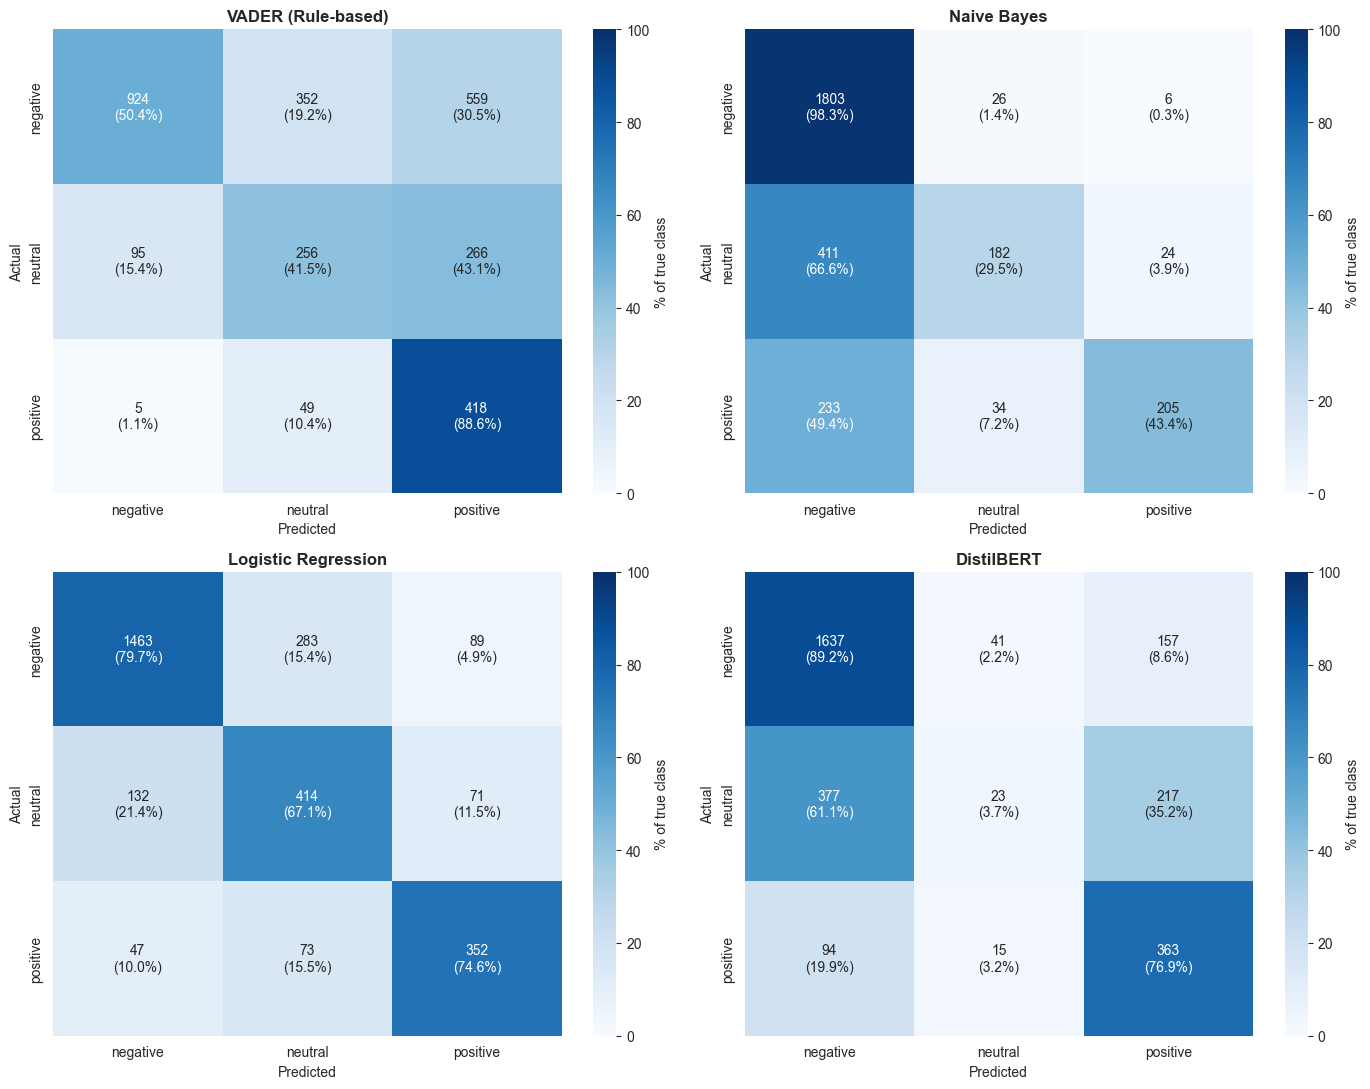

In [4]:
# Helper function buat plot confusion matrix
def plot_cm(y_true, y_pred, title, ax):
    labels = ['negative', 'neutral', 'positive']
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100  # convert to %
    
    # Annotate dengan count + percentage
    annot = np.array([
        [f"{count}\n({pct:.1f}%)" for count, pct in zip(row_c, row_p)]
        for row_c, row_p in zip(cm, cm_pct)
    ])
    
    sns.heatmap(cm_pct, annot=annot, fmt='', cmap='Blues',
                xticklabels=labels, yticklabels=labels, ax=ax,
                cbar_kws={'label': '% of true class'}, vmin=0, vmax=100)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
    ax.set_title(title, fontsize=12, fontweight='bold')

# Plot 2x2 grid: confusion matrix tiap model
fig, axes = plt.subplots(2, 2, figsize=(14, 11))

models_info = [
    ('vader_pred', 'VADER (Rule-based)', axes[0, 0]),
    ('nb_pred', 'Naive Bayes', axes[0, 1]),
    ('lr_pred', 'Logistic Regression', axes[1, 0]),
    ('hf_pred', 'DistilBERT', axes[1, 1]),
]

for col, title, ax in models_info:
    plot_cm(preds['true_label'], preds[col], title, ax)

plt.tight_layout()
plt.savefig('../data/processed/confusion_matrices.png', dpi=100, bbox_inches='tight')
plt.show()

### 📌 Apa yang harus lo perhatiin:

**Diagonal kuat (gelap di pojok)** → model akurat untuk class itu.

**Hot spots di luar diagonal** → pola kesalahan sistematis. Misalnya:
- `(positive → negative)` gelap → model salah pikir tweet positif sebagai negatif
- Kolom `neutral` sepi → model jarang prediksi neutral (under-predict)

### Common pattern di sentiment analysis:
- **VADER** biasanya over-predict positive/negative (gampang misinterpret sarkasme)
- **Naive Bayes** biasanya bias ke majority class (negative di dataset kita)
- **DistilBERT** struggling di neutral (karena binary-trained)
- **Logistic Regression** balanced karena pake `class_weight='balanced'`

---

## 3. Per-Class Metrics Comparison

Akurasi total bisa misleading kalau data imbalanced. Yang lebih informative: **F1-score per class**.

In [5]:
# Compute per-class F1 untuk tiap model
def get_per_class_f1(y_true, y_pred):
    labels = ['negative', 'neutral', 'positive']
    _, _, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    return dict(zip(labels, f1))

f1_data = []
for col, name in [('vader_pred', 'VADER'), ('nb_pred', 'Naive Bayes'), 
                   ('lr_pred', 'Logistic Regression'), ('hf_pred', 'DistilBERT')]:
    f1 = get_per_class_f1(preds['true_label'], preds[col])
    f1_data.append({'Model': name, **f1})

f1_df = pd.DataFrame(f1_data).set_index('Model')
print("F1-score per class:")
print(f1_df.round(3))

F1-score per class:
                     negative  neutral  positive
Model                                           
VADER                   0.646    0.402     0.487
Naive Bayes             0.842    0.424     0.580
Logistic Regression     0.842    0.597     0.715
DistilBERT              0.830    0.066     0.600


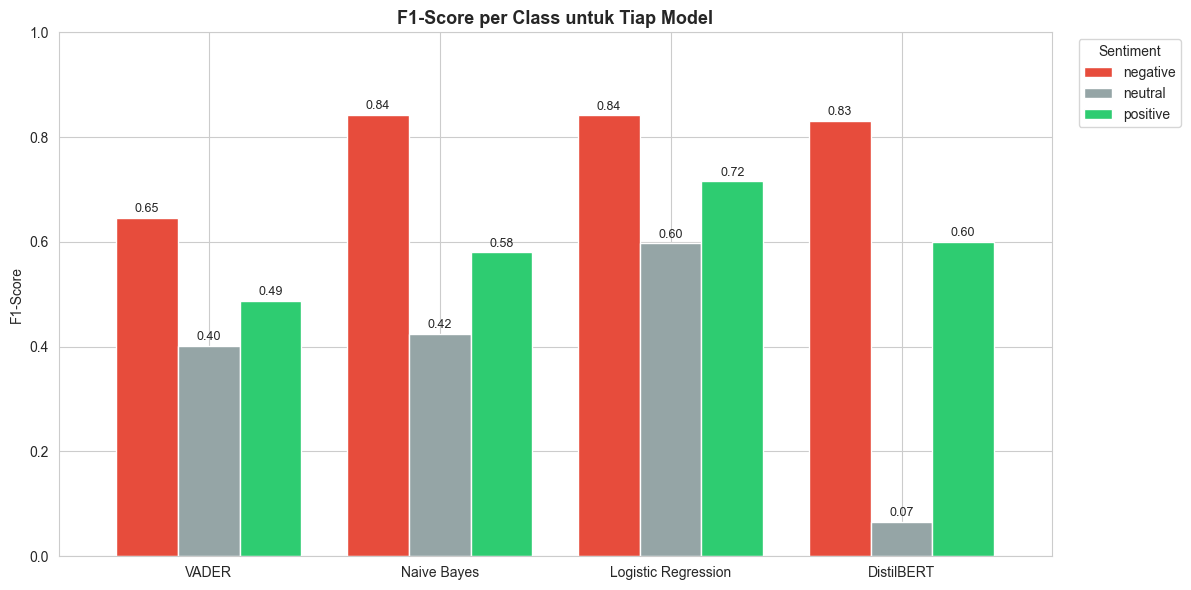

In [6]:
# Visualize as grouped bar chart
fig, ax = plt.subplots(figsize=(12, 6))
f1_df.plot(kind='bar', ax=ax, color=['#e74c3c', '#95a5a6', '#2ecc71'], width=0.8)

ax.set_title('F1-Score per Class untuk Tiap Model', fontsize=13, fontweight='bold')
ax.set_ylabel('F1-Score')
ax.set_xlabel('')
ax.set_ylim(0, 1)
ax.legend(title='Sentiment', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.tick_params(axis='x', rotation=0)

# Annotate bar values
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=2, fontsize=9)

plt.tight_layout()
plt.savefig('../data/processed/f1_per_class.png', dpi=100, bbox_inches='tight')
plt.show()

### 📌 Key insight:

**Class neutral biasanya jadi masalah utama** untuk semua model. Kenapa?
- Neutral itu **ambigu** — kadang mirip positif (info netral yang sopan), kadang mirip negatif (komplain sopan)
- Manusia juga sering salah label neutral!
- Solusi di production: bisa **binary aja (pos vs neg)** + threshold untuk "uncertain"

**Negative biasanya paling tinggi F1** → karena class-nya majority + ekspresi negative lebih distinctive ("worst", "delayed", "cancelled").

---

## 4. Error Analysis — Liat Tweet yang Salah Prediksi

Ini bagian paling **eye-opening**. Kita lihat **kenapa** model salah, bukan cuma berapa salahnya.

Fokus ke **Logistic Regression** (model terbaik kita).

In [7]:
# Tambah kolom: is_correct untuk LR
preds['lr_correct'] = preds['true_label'] == preds['lr_pred']

# Error breakdown
error_breakdown = preds[~preds['lr_correct']].groupby(
    ['true_label', 'lr_pred']
).size().reset_index(name='count').sort_values('count', ascending=False)

print("Top error patterns (LR model):")
print(error_breakdown.head(10).to_string(index=False))

Top error patterns (LR model):
true_label  lr_pred  count
  negative  neutral    283
   neutral negative    132
  negative positive     89
  positive  neutral     73
   neutral positive     71
  positive negative     47


In [8]:
# Sample tweets dari error pattern terbesar
def show_error_examples(true_label, pred_label, n=5):
    errors = preds[
        (preds['true_label'] == true_label) & 
        (preds['lr_pred'] == pred_label)
    ]
    print(f"🔴 Aktual: {true_label.upper()} → 🤖 Prediksi LR: {pred_label.upper()} ({len(errors)} kasus)")
    print("=" * 100)
    for idx, row in errors.head(n).iterrows():
        print(f"  • {row['text_clean']}")
    print()

# Lihat 3 error pattern terbesar
print("🔍 ERROR ANALYSIS — Tweet yang salah diprediksi LR:\n")
top_errors = error_breakdown.head(3)
for _, row in top_errors.iterrows():
    show_error_examples(row['true_label'], row['lr_pred'], n=5)

🔍 ERROR ANALYSIS — Tweet yang salah diprediksi LR:

🔴 Aktual: NEGATIVE → 🤖 Prediksi LR: NEUTRAL (283 kasus)
  • i m going to start charging you for the consistent body pat downs starting to feel like a piece of meat punishedforflying
  • obviously your corporate definition of patience needs to be reviewed pleasehurryup answerphone reschedulemyflight
  • i thank you for the reply but too complicated to dm really would like to talk to a cust rep what is going on there
  • yes of course before i left the airport i kept looking but claim is still open
  • how is it possible that someone is drunk they bring a wheelchair for them but you keep serving them

🔴 Aktual: NEUTRAL → 🤖 Prediksi LR: NEGATIVE (132 kasus)
  • actually flight not
  • we even offered to fly in to another airport and they said they couldn t do that no explanation why they can t
  • i just checked in online for tomorrow s flight thought i should get auto upgrade already got the email saying no seats
  • are we sure flights

### 📌 Apa yang harus lo observe:

Common reasons kenapa model salah:
1. **Sarkasme** — "Thanks for the GREAT delay" → kata "thanks" + "great" muncul tapi sebenernya negatif
2. **Konteks panjang** — tweet panjang dengan opini campuran
3. **Label ambigu** — kadang labeler asli pun debatable (positif/neutral?)
4. **Tweet pendek banget** — "ok flight" → susah klasifikasi

**Insight bisnis:** kalau model salah untuk tweet sarkasme banyak → mungkin perlu pre-filter atau model khusus untuk sarkasme detection.

### Tweet yang SEMUA MODEL SALAH

Kalau semua 4 model salah, kemungkinan **label aslinya ambigu** atau **kasus super sulit**.

In [9]:
# Cari tweet yang semua 4 model salah
all_wrong = preds[
    (preds['vader_pred'] != preds['true_label']) &
    (preds['nb_pred'] != preds['true_label']) &
    (preds['lr_pred'] != preds['true_label']) &
    (preds['hf_pred'] != preds['true_label'])
]

print(f"Tweet yang SEMUA model salah: {len(all_wrong)} ({len(all_wrong)/len(preds)*100:.1f}%)")
print(f"\n10 contoh:")
print("=" * 100)
for idx, row in all_wrong.head(10).iterrows():
    print(f"📝 Tweet: {row['text_clean']}")
    print(f"   True: {row['true_label']} | VADER: {row['vader_pred']} | NB: {row['nb_pred']} | LR: {row['lr_pred']} | HF: {row['hf_pred']}")
    print()

Tweet yang SEMUA model salah: 173 (5.9%)

10 contoh:
📝 Tweet: we even offered to fly in to another airport and they said they couldn t do that no explanation why they can t
   True: neutral | VADER: negative | NB: negative | LR: negative | HF: negative

📝 Tweet: i just checked in online for tomorrow s flight thought i should get auto upgrade already got the email saying no seats
   True: neutral | VADER: negative | NB: negative | LR: negative | HF: negative

📝 Tweet: are we sure flights will not be cancelled flighted after i am trying to make plans in stl
   True: neutral | VADER: positive | NB: negative | LR: negative | HF: positive

📝 Tweet: the only thing you fella have done right today is get me to the pacific time zone
   True: positive | VADER: neutral | NB: negative | LR: neutral | HF: negative

📝 Tweet: got it squared away someone picked up as soon as i tweeted should have tweeted sooner
   True: positive | VADER: neutral | NB: negative | LR: neutral | HF: negative

📝 Tweet: ex

---

## 5. Model Agreement Analysis

Kalau model-model setuju → biasanya bener. Kalau gak setuju → kasus ambigu / sulit.

Ini dipakai untuk **ensemble** (voting) atau **confidence flagging** di production.

In [10]:
# Hitung berapa model yang setuju per row
def count_agreement(row):
    preds_list = [row['vader_pred'], row['nb_pred'], row['lr_pred'], row['hf_pred']]
    return max(preds_list.count(p) for p in set(preds_list))

preds['agreement'] = preds.apply(count_agreement, axis=1)

# Distribusi agreement
agreement_dist = preds['agreement'].value_counts().sort_index()
print("Distribusi agreement (berapa model yang sepakat):")
print(agreement_dist)
print(f"\nDalam persen:")
print((agreement_dist / len(preds) * 100).round(1))

Distribusi agreement (berapa model yang sepakat):
agreement
2     771
3    1111
4    1042
Name: count, dtype: int64

Dalam persen:
agreement
2    26.4
3    38.0
4    35.6
Name: count, dtype: float64


In [11]:
# Akurasi vs agreement
print("Apakah agreement bener-bener ngindikasiin akurasi?")
print()

for agree in sorted(preds['agreement'].unique()):
    subset = preds[preds['agreement'] == agree]
    # Kalau semua setuju → ambil prediksi mana aja sama; kalau beda → ambil LR
    pred_col = 'lr_pred'  # gunakan LR sebagai representative
    acc = (subset[pred_col] == subset['true_label']).mean()
    print(f"  {agree} model setuju → akurasi LR: {acc:.3f} ({len(subset)} samples, {len(subset)/len(preds)*100:.1f}%)")

Apakah agreement bener-bener ngindikasiin akurasi?

  2 model setuju → akurasi LR: 0.527 (771 samples, 26.4%)
  3 model setuju → akurasi LR: 0.757 (1111 samples, 38.0%)
  4 model setuju → akurasi LR: 0.942 (1042 samples, 35.6%)


### 📌 Insight bisnis:

Kalau **3-4 model setuju** → confident, langsung pake hasilnya.
Kalau **cuma 2 yang setuju** → uncertain, mungkin perlu human review.

Pattern ini bisa lo pake di **dashboard** sebagai **confidence indicator**:
- 🟢 4/4 setuju = "High confidence"
- 🟡 3/4 setuju = "Medium confidence"  
- 🔴 2/4 setuju = "Low confidence — review needed"

Ini fitur yang **biasanya pemula gak kepikiran** tapi recruiter suka banget!

---

## 6. Bonus: Simple Ensemble (Majority Voting)

Apa yang terjadi kalau kita ambil **mayoritas vote** dari 4 model?

In [12]:
from collections import Counter

def majority_vote(row):
    votes = [row['vader_pred'], row['nb_pred'], row['lr_pred'], row['hf_pred']]
    return Counter(votes).most_common(1)[0][0]

preds['ensemble_pred'] = preds.apply(majority_vote, axis=1)
ensemble_acc = (preds['ensemble_pred'] == preds['true_label']).mean()

# Compare semua
print("📊 Final Comparison (incl. Ensemble):")
print()
final_results = pd.DataFrame({
    'Model': ['VADER', 'Naive Bayes', 'Logistic Regression', 'DistilBERT', '🎯 Ensemble (Majority)'],
    'Accuracy': [
        (preds['vader_pred'] == preds['true_label']).mean(),
        (preds['nb_pred'] == preds['true_label']).mean(),
        (preds['lr_pred'] == preds['true_label']).mean(),
        (preds['hf_pred'] == preds['true_label']).mean(),
        ensemble_acc,
    ]
}).sort_values('Accuracy', ascending=False).reset_index(drop=True)
final_results['Accuracy %'] = (final_results['Accuracy'] * 100).round(2)
print(final_results[['Model', 'Accuracy %']].to_string(index=False))

📊 Final Comparison (incl. Ensemble):

                Model  Accuracy %
🎯 Ensemble (Majority)       76.37
  Logistic Regression       76.23
          Naive Bayes       74.90
           DistilBERT       69.19
                VADER       54.65


### 📌 Catatan tentang ensemble:

- Kalau ensemble **lebih bagus dari best single model** → pake ensemble di production
- Kalau ensemble **gak ngalahin LR** → mungkin model lemah (VADER, DistilBERT yang struggling) "menarik turun" akurasi
- Trade-off: ensemble lebih **lambat** dan **lebih kompleks**

Di production beneran, kalau improvement ensemble cuma 0.5-1%, biasanya **pake LR aja** karena cost-benefit-nya lebih baik.

---

## 7. 🏆 Final Pick untuk Dashboard

Berdasarkan semua analisis:

In [13]:
# Final summary tabel
summary = pd.DataFrame({
    'Metric': ['Accuracy', 'Speed (s)', 'Interpretability', 'Production-Ready'],
    'VADER': ['54.65%', '0.2', '⭐⭐⭐ (rules)', '⭐⭐⭐ (no train)'],
    'Naive Bayes': ['74.90%', '0.03', '⭐⭐ (probabilities)', '⭐⭐⭐'],
    'Logistic Regression': ['76.23%', '0.31', '⭐⭐⭐ (coefficients)', '⭐⭐⭐'],
    'DistilBERT': ['69.19%', '89.7', '⭐ (black box)', '⭐ (slow)'],
})
summary

,Metric,VADER,Naive Bayes,Logistic Regression,DistilBERT
0,Accuracy,54.65%,74.90%,76.23%,69.19%
1,Speed (s),0.2,0.03,0.31,89.7
2,Interpretability,⭐⭐⭐ (rules),⭐⭐ (probabilities),⭐⭐⭐ (coefficients),⭐ (black box)
3,Production-Ready,⭐⭐⭐ (no train),⭐⭐⭐,⭐⭐⭐,⭐ (slow)


### 🥇 Winner: **Logistic Regression**

**Alasan:**
1. ✅ **Akurasi tertinggi** (76.23%) — ngalahin DistilBERT 7 poin
2. ✅ **Cepet banget** (0.31s untuk 2,924 prediksi) — 290x lebih cepet dari DistilBERT
3. ✅ **Interpretable** — bisa show top words per sentiment (transparency!)
4. ✅ **Production-ready** — file kecil, gak perlu GPU, gak perlu install transformers
5. ✅ **Best F1 di neutral class** — paling balanced

### 🎯 Strategy untuk Dashboard:
- **Primary model: Logistic Regression** (untuk prediksi single tweet & batch)
- **Optional toggle: VADER** (untuk yang mau super cepet & gak butuh akurasi tinggi)
- **DistilBERT TIDAK kita pake** di production — bukan karena jelek, tapi karena LR udah cukup dan ratusan kali lebih cepet

### Yang bisa lo cerita di interview:
> "Saya udah eksplorasi 4 pendekatan: rule-based, classical ML (Naive Bayes & Logistic Regression), dan deep learning (DistilBERT). Hasil paling menarik: **Logistic Regression dengan TF-IDF mengalahkan DistilBERT pre-trained di task ini sebesar 7 poin**, dengan **290x kecepatan lebih tinggi**. Ini menunjukkan kalau pemilihan model harus **task-specific**, bukan ikutan hype. Saya pilih LR untuk production karena keseimbangan akurasi, kecepatan, dan interpretability." 🎤

In [14]:
# Save final summary buat dipake di dashboard
final_summary = {
    'best_model': 'Logistic Regression',
    'best_accuracy': float(results.loc[0, 'Accuracy']) if 'Accuracy' in results.columns else 0.7623,
    'models_compared': 4,
    'total_test_samples': len(preds),
}

import json
with open('../data/processed/final_summary.json', 'w') as f:
    json.dump(final_summary, f, indent=2)

print("✅ Saved final summary: ../data/processed/final_summary.json")
print(json.dumps(final_summary, indent=2))

✅ Saved final summary: ../data/processed/final_summary.json
{
  "best_model": "Logistic Regression",
  "best_accuracy": 0.762311901504788,
  "models_compared": 4,
  "total_test_samples": 2924
}


## 🚀 Next: Streamlit Dashboard!

Sekarang kita punya semua bahan:
- ✅ Trained model (`logistic_regression.pkl` + `tfidf_vectorizer.pkl`)
- ✅ Test predictions (`model_predictions.csv`)
- ✅ Comparison results (`model_results.csv`)
- ✅ Confusion matrices (`confusion_matrices.png`)
- ✅ Original data (`tweets_clean.csv`)

**Saatnya bikin dashboard yang nge-display semua ini secara interaktif!** 🎨